# Image steering overfit

Record an image replacement in AsyncLLM, check differentiable replay, train a student, and reload it for free generation under the same update schedule. See [README](README.md) for setup and configuration.

`SETUP` selects Torch replay attention with query chunks of 64 for parity checks, training, and checkpoint reload. Set `replay_attention_backend="auto"` and `replay_query_chunk_size=1024` to use automatic selection. Use a fresh `RUN` directory when changing settings; cached reports must match.

Images, question, notification, labels, and provenance are loaded from the pinned Hugging Face dataset. The notebook displays dataset images, rollout inspection, training curves, and generation comparisons in its outputs.

## A. Setup

Use one free GPU. Separate child processes release engine/model memory between stages. Sampling is greedy for teacher and student, with a fixed seed; the image event occurs after exactly `update_after` emitted model tokens, excluding input text.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "python/minisgl/training/recording.py").exists()
)
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "scripts"), str(ROOT / "python")]
os.environ["PATH"] = str(Path(sys.executable).parent) + ":/usr/local/cuda/bin:" + os.environ["PATH"]
os.environ.setdefault("CUDA_HOME", "/usr/local/cuda")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ["MPLBACKEND"] = "Agg"

import json
import subprocess
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from minisgl.training import Trace

from minisgl_examples.training.image_steering import experiment as exp
from minisgl_examples.training.process import isolated


def display_figure(fig):
    # Explicit PNG output also works with Agg in headless notebook kernels.
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
        display(DisplayImage(data=buffer.getvalue()))


TEACHER = "Qwen/Qwen3.5-4B"
STUDENT = "Qwen/Qwen3.5-0.8B"
SETUP = exp.asdict(exp.Setup(replay_attention_backend="torch", replay_query_chunk_size=64))
RUN = Path(os.environ.get("IMAGE_STEERING_RUN", ROOT / "training_runs/image_steering_hf"))
RUN.mkdir(parents=True, exist_ok=True)
print(
    subprocess.check_output(
        ["nvidia-smi", "--query-gpu=index,name,memory.used,utilization.gpu", "--format=csv"],
        text=True,
    )
)
print("GPU:", os.environ["CUDA_VISIBLE_DEVICES"], "Run:", RUN)
print(SETUP)


/home/mrozaeva/experiments/image-steering-overfit/repo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


index, name, memory.used [MiB], utilization.gpu [%]
0, NVIDIA H100 80GB HBM3, 79823 MiB, 100 %
1, NVIDIA H100 80GB HBM3, 19557 MiB, 97 %

GPU: 1 Run: /home/mrozaeva/experiments/image-steering-notebook-20261127/training_runs/executed_notebook
{'seed': 7, 'update_after': 96, 'max_tokens': 640, 'max_pixels': 65536, 'kv_tokens': 4096, 'prefill_rows': 128, 'dtype': 'float16', 'replay_attention_backend': 'torch', 'replay_query_chunk_size': 64}


## B. Task: a corrected table cell

MathVista `testmini`, problem 45, from `MrDarkTesla/sharded_vqa` on Hugging Face. Image A says September **20**, image B says **14**; August stays **17**. The rate changes from **+3** to **−3 minutes/month**. Labels are for evaluation only; they never enter inference.

The update contains only image B and a fixed notification that the picture was corrected. It contains no values, answer, or teacher-generated reasoning.

An administrator at the Department of Motor Vehicles (DMV) tracked the average wait time from month to month. According to the table, what was the rate of change between August and September? (Unit: minutes per month)

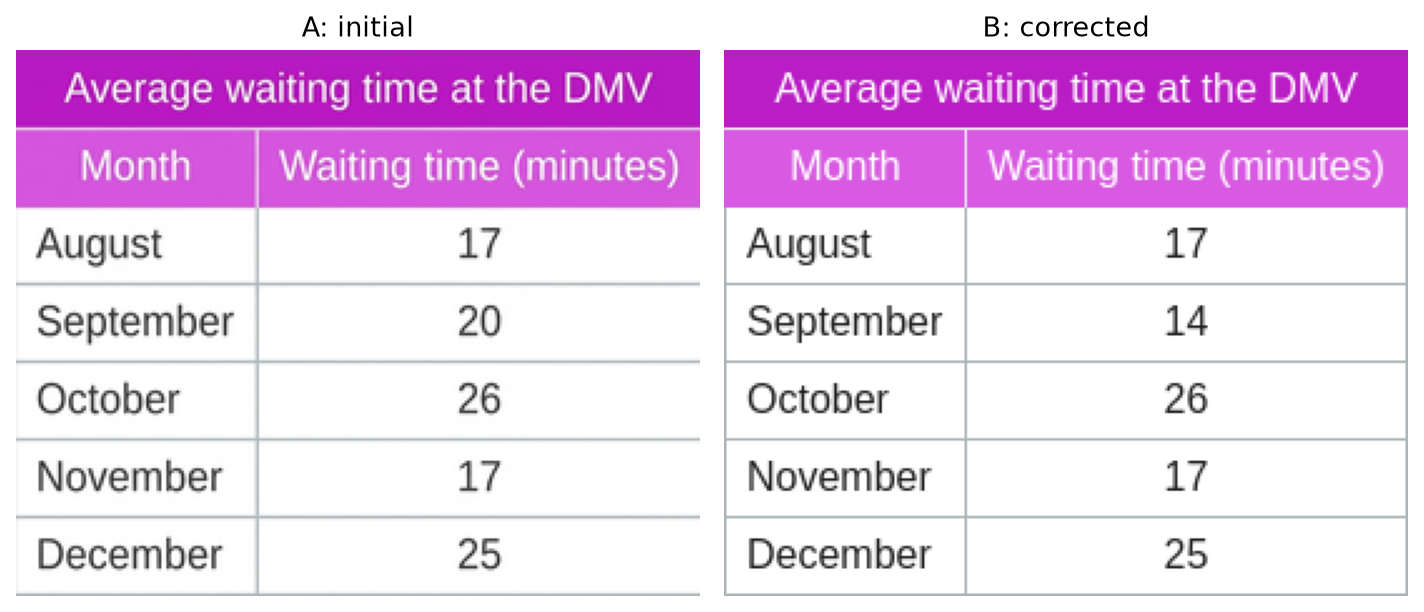

Expected: 3 → -3
External notification: </think><|im_end|>
<|im_start|>user
The earlier picture contained an error. It has now been corrected. Recheck your reasoning using the current picture.<|im_end|>
<|im_start|>assistant
<think>



In [2]:
display(Markdown(exp.task()["question"]))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, side, title in zip(axes, ["before", "after"], ["A: initial", "B: corrected"]):
    ax.imshow(exp.load_image(side))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
display_figure(fig)
plt.close(fig)
print("Expected:", exp.task()["answer_before"], "→", exp.task()["answer_after"])
print("External notification:", exp.notification())


## C. Teacher inference and persistence

Prompt, image, and reasoning occupy separate CacheBlocks. The current reasoning view is `[prompt, image, reasoning]`. At the token barrier the pending emitted token is committed under A; that flush is unsupervised. The old image block is freed, B is encoded into a new block conditioned on the prompt, and the view is replaced. Historical reasoning KV is retained. The notification is prefilled; its final logits produce the first post-update token.

All model tokens are selected from AsyncLLM logits in a single reasoning stream.

In [3]:
def collect_once(model, name, *, update=True, replacement_image="after"):
    path = RUN / f"{name}.json"
    if not path.exists():
        isolated(
            exp.collect,
            model,
            path,
            SETUP,
            update=update,
            replacement_image=replacement_image,
            log_path=RUN / f"{name}.log",
        )
    result = exp.require_replay_options(exp.load(path), SETUP)
    assert result["model"] == str(model)
    assert result["setup"] == SETUP and result["update"] == update
    assert result["task"] == exp.task()
    assert result.get("replacement_image", "after") == replacement_image
    return path, result


teacher_path, teacher = collect_once(TEACHER, "teacher")
print(teacher["assessment"])
print("Before update:\n", teacher["before_update_text"])
print("After update:\n", teacher["after_update_text"])
assert teacher["assessment"][
    "behavior_reproduced"
], "Teacher failed: choose another example/model before training."


{'final_answer': '-3', 'correct_answer': True, 'old_20_before_event': True, 'new_14_after_event': True, 'revision_language_after_event': False, 'behavior_reproduced': True}
Before update:
 The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points:**
    *   Look at the row for "August". The waiting time is 17 minutes.
    *   Look at the row for "September". The waiting time is 20 minutes.

2.  **Understand "rate of change":**
    *   Rate of change is calculated
After update:
 The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points from the table:**
    *   **Month:** August -> **Waiting time:** 17 minutes
    *   **Month:** September -> **Waiting time:** 14 minutes

2.  **Calculate the rate of change:**
    *   The formula for rate of change is $\frac{\text{Change in value}}{\text{Change in time}}$.
    *   Chang

## D. Rollout inspection

Portable format-v2 traces contain requests in execution order: token IDs, write positions, ordered view lengths, image pixels/grids/types, three-axis MRoPE positions, rotary spans, and clear/copy references. They do not contain cached image embeddings or detached numeric KV states. Targets label the row that produced each sampled token; every other row uses `-100`. A global next-token shift would be incorrect here.

In [4]:
inspection = exp.inspect_rollout(teacher_path)
print(json.dumps(teacher["events"], indent=2))
print(json.dumps(inspection, indent=2))


[
  {
    "event": "image_A",
    "generated_tokens": 0,
    "trace_rows": 181,
    "step": 2,
    "blocks": [
      {
        "id": 0,
        "tokens": 106,
        "mrope_span": 106
      },
      {
        "id": 1,
        "tokens": 75,
        "mrope_span": 12
      },
      {
        "id": 2,
        "tokens": 0,
        "mrope_span": 0
      }
    ]
  },
  {
    "event": "update_barrier",
    "generated_tokens": 96,
    "trace_rows": 284,
    "step": 99,
    "blocks": [
      {
        "id": 0,
        "tokens": 106,
        "mrope_span": 106
      },
      {
        "id": 1,
        "tokens": 75,
        "mrope_span": 12
      },
      {
        "id": 2,
        "tokens": 103,
        "mrope_span": 103
      }
    ]
  },
  {
    "event": "image_B",
    "generated_tokens": 96,
    "trace_rows": 359,
    "step": 100,
    "blocks": [
      {
        "id": 0,
        "tokens": 106,
        "mrope_span": 106
      },
      {
        "id": 3,
        "tokens": 75,
        "mrope_span

In [5]:
trace = Trace.from_dict(teacher["trace"])
tok = __import__("transformers").AutoTokenizer.from_pretrained(TEACHER)
k = SETUP["update_after"]
for i in range(max(0, k - 5), min(len(teacher["token_ids"]), k + 8)):
    row = teacher["sample_rows"][i]
    t = trace.tokens[row]
    print(
        {
            "generated_index": i + 1,
            "phase": teacher["sample_phases"][i],
            "text": tok.decode([teacher["token_ids"][i]]),
            "target_row": row,
            "input_position": t.position,
            "step": t.step,
            "view": t.view,
            "inference_logprob": teacher["logprobs"][row],
        }
    )


{'generated_index': 92, 'phase': 'before', 'text': ' Rate', 'target_row': 278, 'input_position': 97, 'step': 93, 'view': ((0, 106), (1, 75), (2, 98)), 'inference_logprob': -0.13755400478839874}
{'generated_index': 93, 'phase': 'before', 'text': ' of', 'target_row': 279, 'input_position': 98, 'step': 94, 'view': ((0, 106), (1, 75), (2, 99)), 'inference_logprob': -1.1920928244535389e-07}
{'generated_index': 94, 'phase': 'before', 'text': ' change', 'target_row': 280, 'input_position': 99, 'step': 95, 'view': ((0, 106), (1, 75), (2, 100)), 'inference_logprob': -1.6331539882230572e-05}
{'generated_index': 95, 'phase': 'before', 'text': ' is', 'target_row': 281, 'input_position': 100, 'step': 96, 'view': ((0, 106), (1, 75), (2, 101)), 'inference_logprob': -0.08862093836069107}
{'generated_index': 96, 'phase': 'before', 'text': ' calculated', 'target_row': 282, 'input_position': 101, 'step': 97, 'view': ((0, 106), (1, 75), (2, 102)), 'inference_logprob': -0.7906643152236938}
{'generated_inde

## E. Replay parity before updating weights

`replay_trace` applies the actual cache visibility and block-relative MRoPE; attention performs one softmax over each complete view. GDN rebuilds the recurrent computation in view order. Both saved images are re-encoded through the vision tower. Ordinary flattened causal teacher forcing is never used.

First compare teacher inference with teacher replay on the **same weights**, separately before/after replacement. FP16 inference versus replay is numerical, not bitwise; maximum absolute target-logprob error must be ≤0.1. For the student, the same check uses its own baseline trajectory, not the teacher's logprobs.

In [6]:
teacher_parity_path = RUN / "teacher_parity.json"
if not teacher_parity_path.exists():
    isolated(
        exp.check_replay,
        teacher_path,
        teacher_parity_path,
        dtype="float16",
        log_path=RUN / "teacher_parity.log",
    )
teacher_parity = exp.require_replay_options(exp.load(teacher_parity_path), SETUP)
print({k: v for k, v in teacher_parity["parity"].items() if k != "errors"})
assert teacher_parity["parity"]["passed"]


{'max_abs_logprob_error': 0.06000709533691406, 'mean_abs_logprob_error': 0.001150899955500365, 'by_phase': {'before': {'count': 96, 'max_abs': 0.03886371850967407}, 'after': {'count': 417, 'max_abs': 0.06000709533691406}}, 'argmax_target_accuracy': 1.0, 'tolerance': 0.1, 'passed': True}


### Student before training

This is a standalone free-running rollout through AsyncLLM with identical inputs, agent configuration, decoding, token budget, and image-update trigger. No teacher tokens are supplied.

In [7]:
before_path, before = collect_once(STUDENT, "student_before")
print(before["assessment"])
print(before["text"])


{'final_answer': None, 'correct_answer': False, 'old_20_before_event': True, 'new_14_after_event': True, 'revision_language_after_event': True, 'behavior_reproduced': False}
The user wants me to calculate the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points:**
    *   I need the waiting time for August. Looking at the table, the row for "August" shows a waiting time of 17 minutes.
    *   I need the waiting time for September. Looking at the table, the row for "September" shows a waiting time of 20The user has corrected the picture. I need to look at the current image to find the data points for August and September.

1.  **Locate August:** The first row of data is labeled "August". The corresponding value in the "Waiting time (minutes)" column is 17.
2.  **Locate September:** The second row of data is labeled "September". The corresponding value in the "Waiting time (minutes)" column is 14.
3.  **Calculate the rate of ch

## F. One-trajectory overfit

Reuse the shared chunked loss and `Trace.to("cuda")`; optimize the student's language parameters with AdamW (3e-6) in FP32. The vision tower is frozen for memory, but its outputs for A/B are recomputed in replay. No loss is applied to user/prompt/image/notification inputs or flushes.

The loop checks finite nonzero gradients and a real parameter delta. It evaluates every five updates and stops at 100% teacher-forced token accuracy with ≥0.95 probability for the complete teacher sequence, or at the step budget. This threshold is **not** the free-generation success criterion.

In [8]:
training_path = RUN / "trained_low_lr/training.json"
if not training_path.exists():
    isolated(
        exp.train,
        teacher_path,
        STUDENT,
        before_path,
        RUN / "trained_low_lr",
        steps=80,
        lr=3e-6,
        log_path=RUN / "training_low_lr.log",
    )
training = exp.require_replay_options(exp.load(training_path), SETUP)
print("Loss:", training["initial"]["loss"], "→", training["final"]["loss"])
print("Accuracy:", training["initial"]["accuracy"], "→", training["final"]["accuracy"])
print("Parameter max delta:", training["tracked_parameter_max_delta"])
assert training["tracked_parameter_max_delta"] > 0
student_parity = exp.require_replay_options(
    exp.load(RUN / "trained_low_lr/student_initial_parity.json"), SETUP
)
print(
    "Student own-trajectory parity:",
    {k: v for k, v in student_parity["parity"].items() if k != "errors"},
)


Loss: 0.19900363683700562 → 8.27987096272409e-05
Accuracy: 0.9298245614035088 → 1.0
Parameter max delta: 2.8369948267936707e-05
Student own-trajectory parity: {'max_abs_logprob_error': 0.011498987674713135, 'mean_abs_logprob_error': 0.000806858927198173, 'by_phase': {'before': {'count': 96, 'max_abs': 0.007258296012878418}, 'after': {'count': 544, 'max_abs': 0.011498987674713135}}, 'argmax_target_accuracy': 1.0, 'tolerance': 0.1, 'passed': True}


## G. Evaluation: training reproduction, free generation, before/after

Loss/token probabilities measure teacher forcing. The following reload and free-running runs measure the saved checkpoint. The update remains an external token-count event and is never replaced with teacher reasoning.

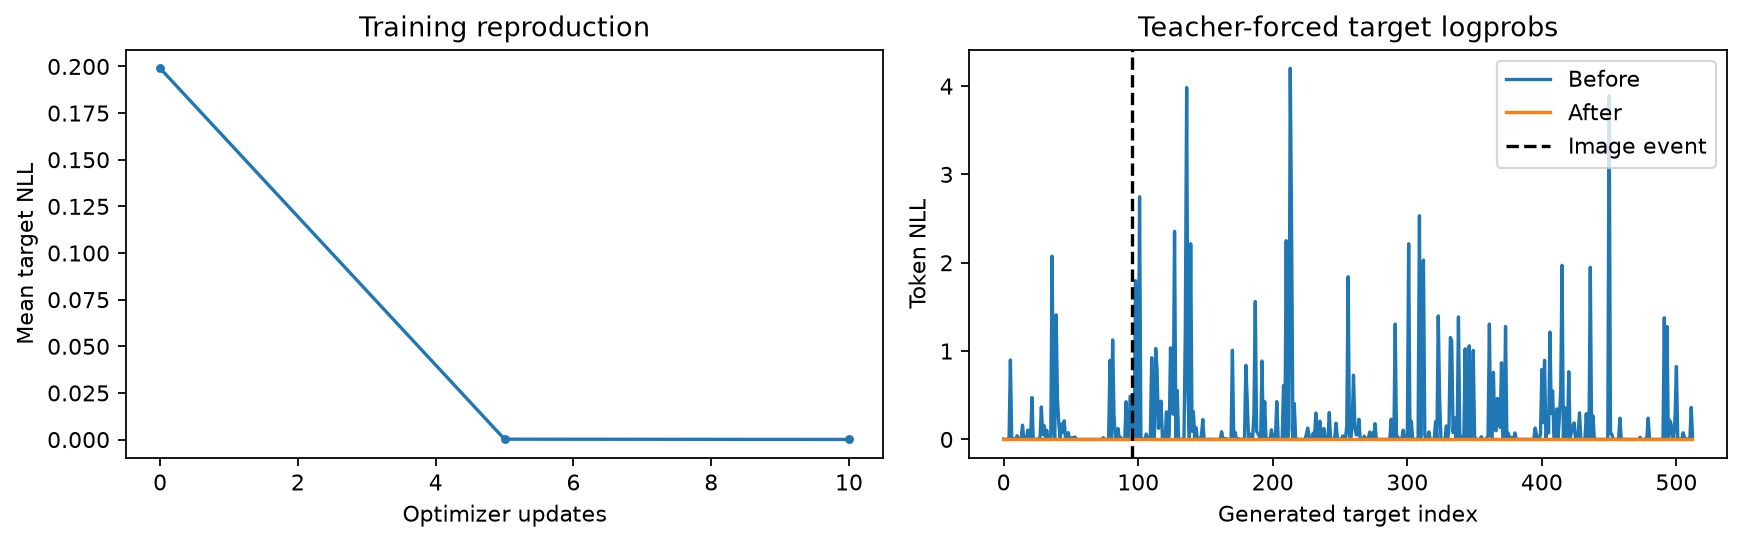

In [9]:
history = training["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([r["step"] for r in history], [r["loss"] for r in history], marker=".")
axes[0].set(xlabel="Optimizer updates", ylabel="Mean target NLL", title="Training reproduction")
initial_nll = training["initial"]["examples"][0]["nll"]
final_nll = training["final"]["examples"][0]["nll"]
axes[1].plot(initial_nll, label="Before")
axes[1].plot(final_nll, label="After")
axes[1].axvline(SETUP["update_after"] - 0.5, color="black", linestyle="--", label="Image event")
axes[1].set(
    xlabel="Generated target index", ylabel="Token NLL", title="Teacher-forced target logprobs"
)
axes[1].legend()
plt.tight_layout()
display_figure(fig)
plt.close(fig)


In [10]:
checkpoint = RUN / "trained_low_lr/checkpoint"
reload_path = RUN / "checkpoint_reload_low_lr.json"
if not reload_path.exists():
    isolated(
        exp.verify_checkpoint,
        teacher_path,
        checkpoint,
        training_path,
        reload_path,
        log_path=RUN / "checkpoint_reload_low_lr.log",
    )
print(
    "Checkpoint retains training replay:",
    exp.require_replay_options(exp.load(reload_path), SETUP)["passed"],
)
after_path, after = collect_once(checkpoint, "student_after_low_lr")
control_path, control = collect_once(checkpoint, "student_without_update_low_lr", update=False)
for name, run in [("After: image replacement", after), ("After: no image update", control)]:
    display(Markdown(f"### {name}"))
    print(run["assessment"])
    print("Before event:\n", run["before_update_text"])
    print("After event:\n", run["after_update_text"])


Checkpoint retains training replay: True


### After: image replacement

{'final_answer': '-3', 'correct_answer': True, 'old_20_before_event': True, 'new_14_after_event': True, 'revision_language_after_event': False, 'behavior_reproduced': True}
Before event:
 The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points:**
    *   Look at the row for "August". The waiting time is 17 minutes.
    *   Look at the row for "September". The waiting time is 20 minutes.

2.  **Understand "rate of change":**
    *   Rate of change is calculated
After event:
 The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points from the table:**
    *   **Month:** August -> **Waiting time:** 17 minutes
    *   **Month:** September -> **Waiting time:** 14 minutes

2.  **Calculate the rate of change:**
    *   The formula for rate of change is $\frac{\text{Change in value}}{\text{Change in time}}$.
    *   Change 

### After: no image update

{'final_answer': '3', 'correct_answer': True, 'old_20_before_event': True, 'new_14_after_event': False, 'revision_language_after_event': False, 'behavior_reproduced': False}
Before event:
 The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points:**
    *   Look at the row for "August". The waiting time is 17 minutes.
    *   Look at the row for "September". The waiting time is 20 minutes.

2.  **Understand "rate of change":**
    *   Rate of change is calculated by finding the difference in value divided by the difference in time.
    *   Formula: $\frac{\text{Waiting time in September} - \text{Waiting time in August}}{ \text{September} - \text{August} }$

3.  **Perform the calculation:**
    *   Difference in waiting time = (Waiting time in September) - (Waiting time in August)
    *   Difference in waiting time = $20 - 17 = 3$ minutes.
    *   Difference in time = September - August = 1 month.
    

In [11]:
comparison_path = RUN / "comparison_low_lr.json"
if not comparison_path.exists():
    exp.compare(teacher_path, before_path, after_path, control_path, comparison_path)
comparison = exp.require_replay_options(exp.load(comparison_path), SETUP)
columns = [
    "correct_answer",
    "behavior_reproduced",
    "exact_tokens",
    "matching_prefix_tokens",
    "token_sequence_similarity",
    "same_external_events",
]
print("metric".ljust(30), "before".ljust(16), "after".ljust(16), "no update")
for key in columns:
    print(
        key.ljust(30),
        *(
            str(comparison["runs"][name][key]).ljust(16)
            for name in ("before", "after", "without_update")
        ),
    )
print("Free-running behavioral success:", comparison["free_running_success"])
print("Exact full-trajectory reproduction:", comparison["exact_trajectory_reproduction"])
print("Visual counterfactual:", comparison["visual_counterfactual_passed"])


metric                         before           after            no update
correct_answer                 False            True             True            
behavior_reproduced            False            True             False           
exact_tokens                   False            True             False           
matching_prefix_tokens         5                513              96              
token_sequence_similarity      0.33304423243712056 1.0              0.8110316649642493
same_external_events           True             True             False           
Free-running behavioral success: True
Exact full-trajectory reproduction: True
Visual counterfactual: True


### Same event and notification, unchanged pixels

Replace A with A at the same token barrier and deliver exactly the same correction notice. The expected answer remains +3. This separates the new visual evidence from the mere presence of an update notification.

In [12]:
pixel_path, pixel_run = collect_once(
    checkpoint, "student_same_image_low_lr", replacement_image="before"
)
pixel_report_path = RUN / "pixel_control_low_lr.json"
if not pixel_report_path.exists():
    exp.compare_pixel_control(teacher_path, after_path, pixel_path, pixel_report_path)
pixel_control = exp.require_replay_options(exp.load(pixel_report_path), SETUP)
print(json.dumps(pixel_control, indent=2))
print(pixel_run["after_update_text"])
assert pixel_control["passed"], "New-pixel dependence has not been established."


{
  "replay_options": {
    "attention_backend": "torch",
    "query_chunk_size": 64
  },
  "same_nonvisual_inputs": true,
  "same_external_events": true,
  "identical_A_pixels_reused": true,
  "with_B": {
    "final_answer": "-3",
    "correct_answer": true,
    "old_20_before_event": true,
    "new_14_after_event": true,
    "revision_language_after_event": false,
    "behavior_reproduced": true
  },
  "with_A_again": {
    "final_answer": "3",
    "correct_answer": true,
    "old_20_before_event": true,
    "new_14_after_event": false,
    "revision_language_after_event": false,
    "behavior_reproduced": false
  },
  "passed": true
}
The user wants me to find the rate of change between August and September based on the provided table.

1.  **Identify the relevant data points from the table:**
    *   **Month:** August -> **Waiting time:** 17 minutes
    *   **Month:** September -> **Waiting time:** 20 minutes

2.  **Calculate the rate of change:**
    *   The formula for rate of ch

The semantic checks are explicit task-specific evidence flags: teacher/student mention the old table value before the event, read the new value afterward, reach the revised answer, and finish. They do not claim to judge arbitrary reasoning equivalence. Compare the phase texts and event records above as well as the token metrics.

The no-update control checks whether the answer follows the image state. The additional A→A control keeps the event and notification identical while withholding the corrected pixels, isolating the visual contribution. Exact token reproduction and the control result are reported independently from behavioral reproduction. A reduced loss alone never marks this experiment successful.

In [13]:
if not (comparison["free_running_success"] and pixel_control["passed"]):
    display(
        Markdown(
            "**Experiment incomplete:** free-running behavior did not satisfy the explicit trajectory checks. Inspect `comparison.json` and both phase texts; a lower training loss does not establish success."
        )
    )
else:
    display(
        Markdown(
            "**Free-running behavioral reproduction passed** under the fixed async schedule. See the separate exact-token and counterfactual results above."
        )
    )
print("Visual control with identical notification:", pixel_control["passed"])
print("Artifacts:", RUN)
print("Teacher logprob max error:", teacher_parity["parity"]["max_abs_logprob_error"])
print("Student logprob max error:", student_parity["parity"]["max_abs_logprob_error"])


**Free-running behavioral reproduction passed** under the fixed async schedule. See the separate exact-token and counterfactual results above.

Visual control with identical notification: True
Artifacts: /home/mrozaeva/experiments/image-steering-notebook-20261127/training_runs/executed_notebook
Teacher logprob max error: 0.06000709533691406
Student logprob max error: 0.011498987674713135
